In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline

In [3]:
df = pd.read_csv('../data/processed/cleaned_hr_data.csv')
print(f"Data Shape: {df.shape}")
print(f"Columns: {len(df.columns)}")
print(f"Total Records: {len(df):,}")

Data Shape: (50124, 26)
Columns: 26
Total Records: 50,124


In [4]:
df.head()

,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,...,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
0,27,Male,65.061656,83.842578,75.856526,Computer Science,58.221909,89.566305,64.474484,79.548913,...,5.805850,Tier 3,Not Matched,Medium,Not Required,15.0,No,18.0,Not Willing,Not Placed
1,24,Male,67.885626,64.973305,73.093588,Electronics,71.927978,54.591971,61.077306,73.316134,...,10.807739,Tier 1,Matched,High,Required,0.0,No,0.0,Not Willing,Not Placed
2,33,Female,73.892471,68.834121,90.196460,Information Technology,72.445041,58.587088,79.494739,75.466980,...,5.476839,Tier 3,Not Matched,Low,Not Required,0.0,No,3.0,Not Willing,Placed
3,31,Male,74.145568,76.255126,75.586731,Mechanical,78.855676,61.022065,53.740386,73.676449,...,9.980580,Tier 2,Matched,Low,Not Required,0.0,Yes,6.0,Not Willing,Not Placed
4,28,Male,60.475937,65.786336,80.801010,Information Technology,68.286776,65.713731,61.438314,88.994847,...,8.921233,Tier 2,Matched,Medium,Not Required,0.0,No,3.0,Willing,Not Placed


In [5]:
# Target variable analysis
print("\n TARGET VARIABLE ANALYSIS:")
status_counts = df['status'].value_counts()
placement_rate = (status_counts['Placed'] / len(df)) * 100 if 'Placed' in status_counts.index else 0

print(f"• Placement Distribution:")
for status, count in status_counts.items():
    percentage = (count / len(df)) * 100
    print(f"  {status}: {count:,} candidates ({percentage:.1f}%)")

print(f"• Overall Placement Rate: {placement_rate:.1f}%")


 TARGET VARIABLE ANALYSIS:
• Placement Distribution:
  Not Placed: 34,950 candidates (69.7%)
  Placed: 15,174 candidates (30.3%)
• Overall Placement Rate: 30.3%


Visualization

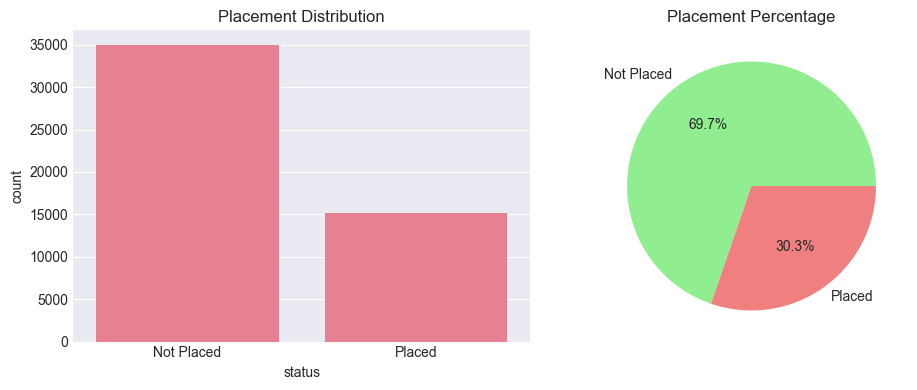

In [6]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
sns.countplot(x='status', data=df)
plt.title("Placement Distribution")

plt.subplot(1,2,2)
plt.pie(status_counts.values,
        labels=status_counts.index,
        autopct='%1.1f%%',
        colors=['lightgreen','lightcoral'])
plt.title("Placement Percentage")

plt.tight_layout()
plt.show()


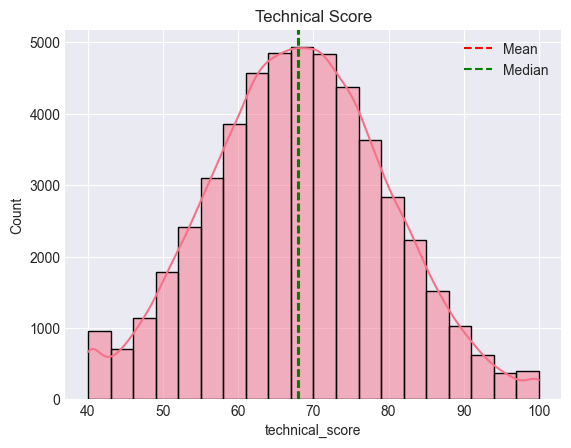

technical_score: Mean=68.0, Median=68.0


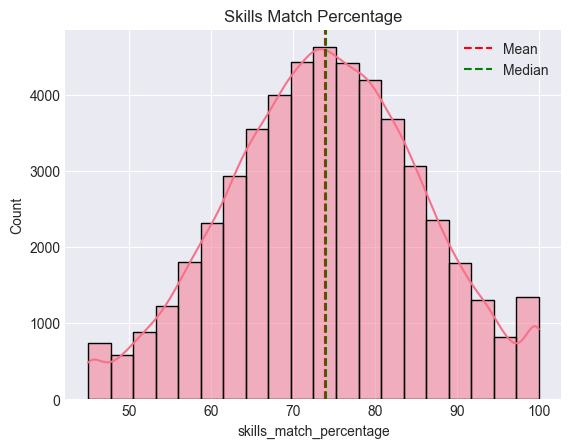

skills_match_percentage: Mean=73.9, Median=74.0


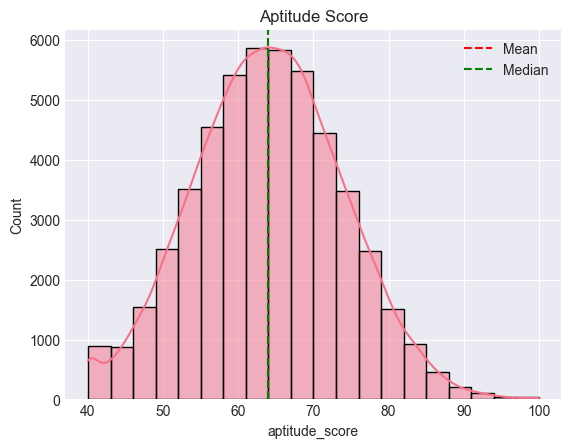

aptitude_score: Mean=64.0, Median=64.0


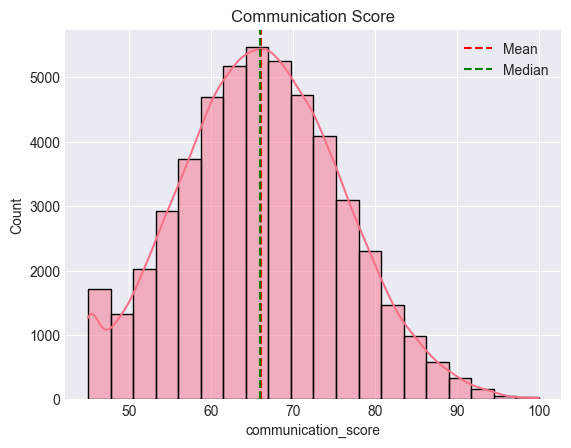

communication_score: Mean=66.1, Median=66.0


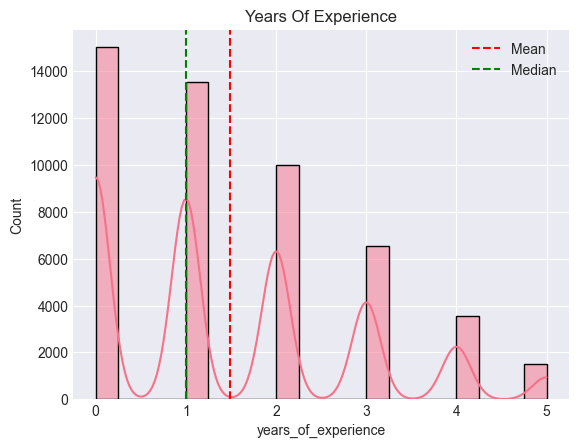

years_of_experience: Mean=1.5, Median=1.0


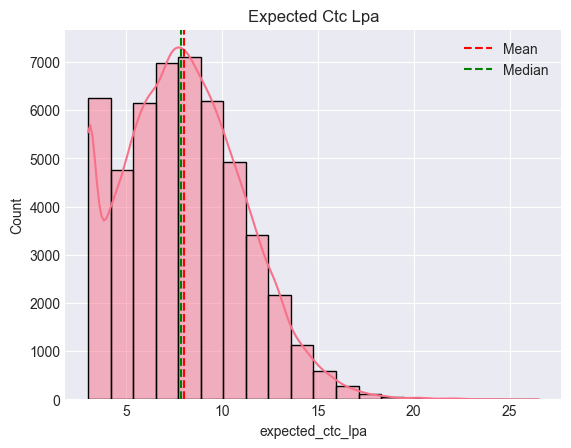

expected_ctc_lpa: Mean=8.0, Median=7.9


In [7]:
important_features = [
    'technical_score',
    'skills_match_percentage',
    'aptitude_score',
    'communication_score',
    'years_of_experience',
    'expected_ctc_lpa'
]

for feature in important_features:
    plt.figure()
    sns.histplot(df[feature], bins=20, kde=True)
    plt.axvline(df[feature].mean(), color='red', linestyle='--', label='Mean')
    plt.axvline(df[feature].median(), color='green', linestyle='--', label='Median')
    plt.title(feature.replace('_',' ').title())
    plt.legend()
    plt.show()

    print(f"{feature}: Mean={df[feature].mean():.1f}, Median={df[feature].median():.1f}")


In [8]:
df['is_placed'] = df['status'].map({'Placed':1, 'Not Placed':0})


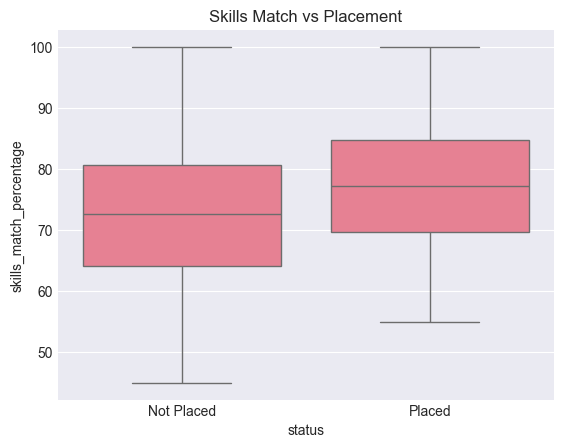

In [9]:
#Skills Match

sns.boxplot(x='status', y='skills_match_percentage', data=df)
plt.title("Skills Match vs Placement")
plt.show()

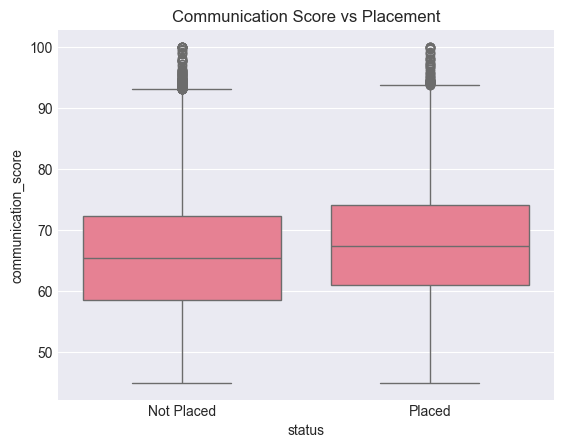

In [10]:
# Communication Score

sns.boxplot(x='status', y='communication_score', data=df)
plt.title("Communication Score vs Placement")
plt.show()


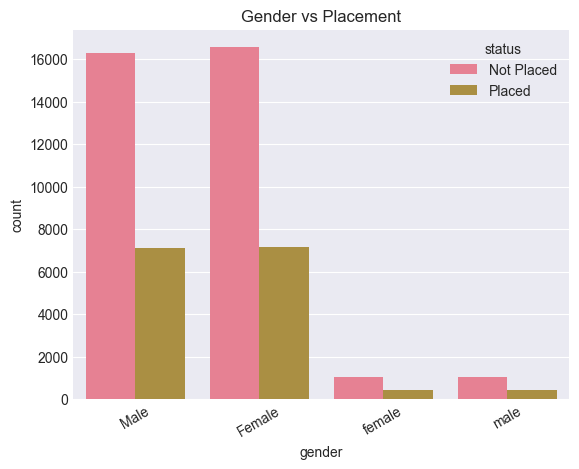


Placement Rate by gender:
gender
Female    30.2
Male      30.4
female    30.1
male      30.2
Name: is_placed, dtype: float64


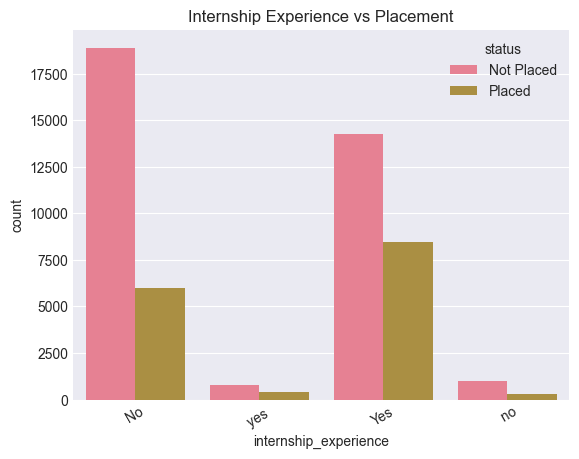


Placement Rate by internship_experience:
internship_experience
 no     24.5
No      24.1
Yes     37.2
yes     34.3
Name: is_placed, dtype: float64


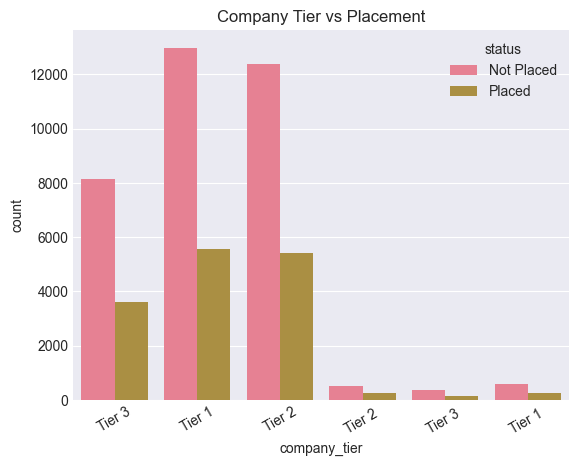


Placement Rate by company_tier:
company_tier
Tier 1     29.9
Tier 1     30.4
Tier 2     30.3
Tier 2     32.4
Tier 3     30.6
Tier 3     28.7
Name: is_placed, dtype: float64


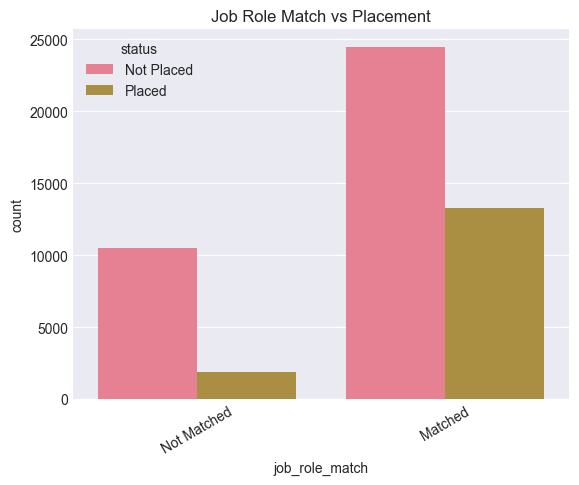


Placement Rate by job_role_match:
job_role_match
Matched        35.2
Not Matched    15.2
Name: is_placed, dtype: float64


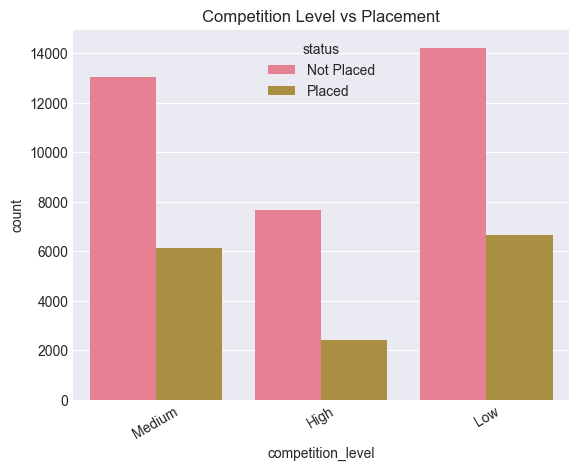


Placement Rate by competition_level:
competition_level
High      23.8
Low       31.9
Medium    31.9
Name: is_placed, dtype: float64


In [11]:
categorical_cols = [
    'gender',
    'internship_experience',
    'company_tier',
    'job_role_match',
    'competition_level'
]

for col in categorical_cols:
    plt.figure()
    sns.countplot(x=col, hue='status', data=df)
    plt.title(f"{col.replace('_',' ').title()} vs Placement")
    plt.xticks(rotation=30)
    plt.show()

    rate = df.groupby(col)['is_placed'].mean()*100
    print(f"\nPlacement Rate by {col}:")
    print(rate.round(1))


In [12]:
numeric_cols = df.select_dtypes(include='number')

corr_with_target = numeric_cols.corr()['is_placed'].sort_values(
    key=lambda x: abs(x), ascending=False
)

print("\nTop Correlated Features:")
print(corr_with_target.head(10))



Top Correlated Features:
is_placed                  1.000000
technical_score            0.403767
years_of_experience        0.331089
skills_match_percentage    0.198426
expected_ctc_lpa          -0.161764
previous_ctc_lpa           0.101423
communication_score        0.097696
employment_gap_months     -0.073539
notice_period_days        -0.051266
aptitude_score             0.039454
Name: is_placed, dtype: float64


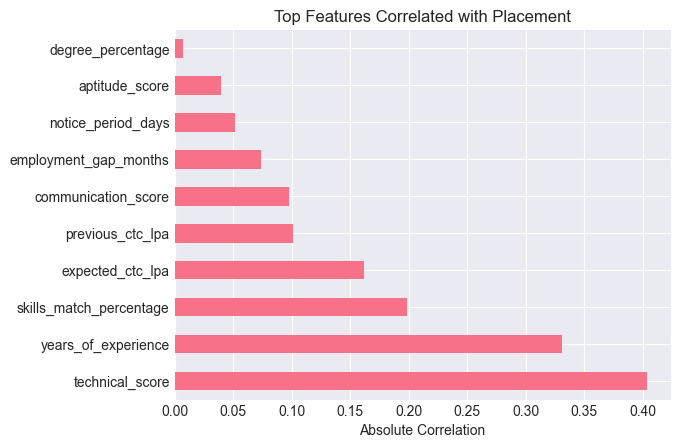

In [13]:
corr_with_target.drop('is_placed').head(10).abs().plot(kind='barh')
plt.title("Top Features Correlated with Placement")
plt.xlabel("Absolute Correlation")
plt.show()


Key Insights:
Skills match, interview and technical scores dominate placement decision.

Skills Match Buckets

C:\Users\user\AppData\Local\Temp\ipykernel_12584\1103940424.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  skills_rate = df.groupby('skills_bucket')['is_placed'].mean()*100


skills_bucket
Low           0.0
Medium       22.6
High         33.3
Excellent    41.4
Name: is_placed, dtype: float64


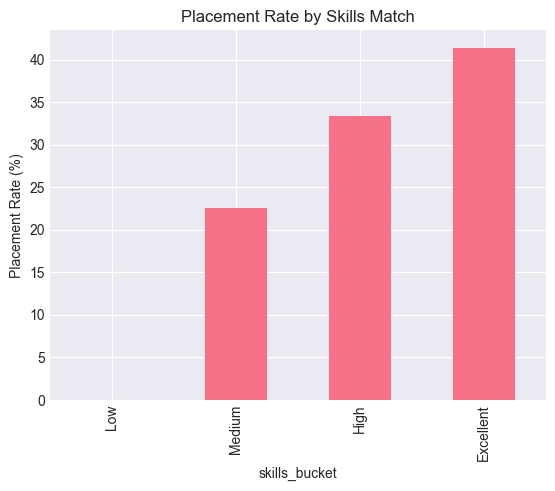

In [14]:
df['skills_bucket'] = pd.cut(
    df['skills_match_percentage'],
    bins=[0,50,70,85,100],
    labels=['Low','Medium','High','Excellent']
)

skills_rate = df.groupby('skills_bucket')['is_placed'].mean()*100
print(skills_rate.round(1))

skills_rate.plot(kind='bar')
plt.ylabel("Placement Rate (%)")
plt.title("Placement Rate by Skills Match")
plt.show()


Experience Analysis

C:\Users\user\AppData\Local\Temp\ipykernel_12584\1946632258.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  exp_rate = df.groupby('exp_category')['is_placed'].mean()*100


exp_category
Fresher    13.8
Junior     29.2
Mid        53.7
Senior      NaN
Expert      NaN
Name: is_placed, dtype: float64


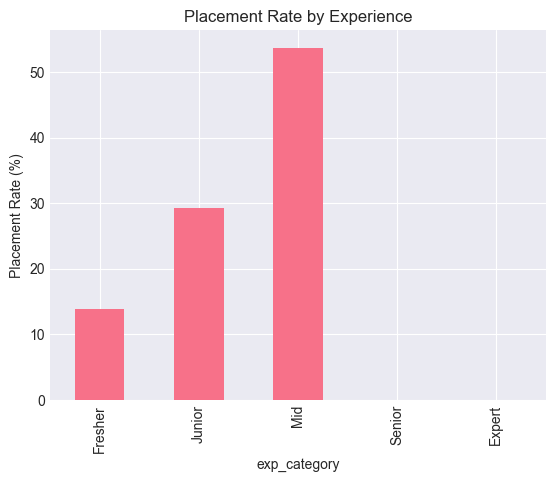

In [15]:
df['exp_category'] = pd.cut(
    df['years_of_experience'],
    bins=[-1,0,2,5,10,100],
    labels=['Fresher','Junior','Mid','Senior','Expert']
)

exp_rate = df.groupby('exp_category')['is_placed'].mean()*100
print(exp_rate.round(1))

exp_rate.plot(kind='bar')
plt.ylabel("Placement Rate (%)")
plt.title("Placement Rate by Experience")
plt.show()


CTC Expectation Analysis

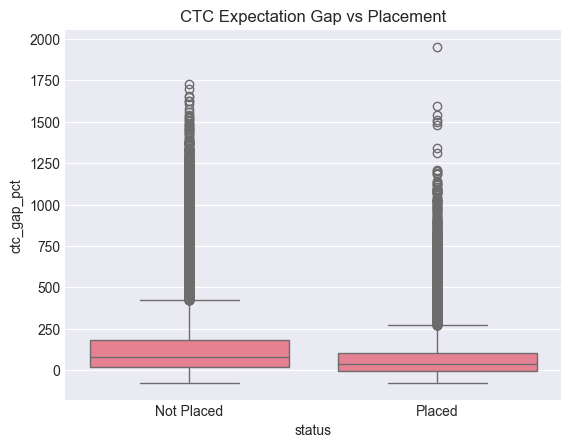

Avg CTC Gap (Placed): 78.6
Avg CTC Gap (Not Placed): 142.9


In [16]:
df['ctc_gap_pct'] = ((df['expected_ctc_lpa'] - df['previous_ctc_lpa']) /
                     df['previous_ctc_lpa'].replace(0,1)) * 100

sns.boxplot(x='status', y='ctc_gap_pct', data=df)
plt.title("CTC Expectation Gap vs Placement")
plt.show()

print("Avg CTC Gap (Placed):", df[df['is_placed']==1]['ctc_gap_pct'].mean().round(1))
print("Avg CTC Gap (Not Placed):", df[df['is_placed']==0]['ctc_gap_pct'].mean().round(1))
